## DATASET EXPLORATION
This notebook performs a preliminary analysis on the AMLEC data, including graphical visualizations and descriptive statistics.

#### Imports

In [1]:
from pathlib import Path
import os
import sys

_cwd = Path.cwd()
_project_candidates = [_cwd, *_cwd.parents]
_project_candidates.extend(parent / "Masters_Thesis" for parent in tuple(_project_candidates))
_PROJECT_ROOT = next(
    (candidate for candidate in _project_candidates if (candidate / "src" / "globals.py").is_file()),
    None,
)
if _PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate Masters_Thesis/src/globals.py from the current working directory.")
_SRC_DIR = str(_PROJECT_ROOT / "src")
if _SRC_DIR not in sys.path:
    sys.path.insert(0, _SRC_DIR)
os.chdir(_PROJECT_ROOT / "thesis_results")

import importlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

import globals
import utils

np.set_printoptions(precision=4, suppress=True, linewidth=np.inf, threshold=np.inf)

pd.set_option("display.width", 1000)
pd.set_option("display.max_columns", None)

In [2]:
importlib.reload(globals)
importlib.reload(utils)

<module 'utils' from 'c:\\Users\\Matteo\\Desktop\\Scuola\\MastersThesis\\Masters_Thesis\\utils.py'>

#### Path definition and file inspection

In [3]:
param_names, function_names = utils.inspect_metadata(globals.CURRENT_TRAIN_FILE)

Keys in train_file: ['I0', 'LUTdata', 'LUTheader', 'dynamic', 'static', 'wvl']

Attributes in LUTheader (inputs):
  varnames: O3STR,H2OSTR,VIS,G,ASTMX,SSA,PARM2,OBSZEN,PARM1

Attributes in train_file (outputs):
  RTMname: MODTRAN6
  inputmode: Latin hypercube
  lut_package_date: 22-Jun-2025
  opmode: Transfer Functions
  outnames: Lp0,Edir0,Edif0,S,tdir,tdif
  sensor: Empty(dtype=dtype('O'))

LUTheader shape: (10000, 9)
LUTdata shape: (10000, 25230)
wvl shape: (1, 4205)


In [4]:
_, _ = utils.inspect_metadata(globals.TEST_FILE_A_INTERP)

Keys in train_file: ['I0', 'LUTdata', 'LUTheader', 'dynamic', 'static', 'wvl']

Attributes in LUTheader (inputs):
  varnames: O3STR,H2OSTR,VIS,G,ASTMX,SSA,PARM2,OBSZEN,PARM1

Attributes in train_file (outputs):
  RTMname: MODTRAN6
  inputmode: Latin hypercube
  lut_package_date: 16-Apr-2025
  opmode: At-sensor radiance
  outnames: L
  sensor: Empty(dtype=dtype('O'))

LUTheader shape: (10000, 9)
LUTdata shape: (10000, 4205)
wvl shape: (1, 4205)


## Dataset loading and exploration

In [5]:
# load data
X, Y, wavelengths = utils.load_train_h5(globals.CURRENT_TRAIN_FILE)
X_test_amlec_interp, Y_test_amlec_interp, _ = utils.load_train_h5(globals.TEST_FILE_A_INTERP)
X_test_amlec_extrap, Y_test_amlec_extrap, _ = utils.load_train_h5(globals.TEST_FILE_A_EXTRAP)

# inspect shapes
print("X:", X.shape)
print("Y:", Y.shape)
print("X_test_amlec interp:", X_test_amlec_interp.shape)
print("Y_test_amlec interp:", Y_test_amlec_interp.shape)
print("X_test_amlec extrap:", X_test_amlec_extrap.shape)
print("Y_test_amlec extrap:", Y_test_amlec_extrap.shape)
wavelengths = wavelengths.squeeze()
print("wavelengths:", wavelengths.shape)

Y_resh = Y.reshape(-1, Y.shape[1] // len(wavelengths), len(wavelengths))
print("Y reshaped:", Y_resh.shape)

X: (10000, 9)
Y: (10000, 25230)
X_test_amlec interp: (10000, 9)
Y_test_amlec interp: (10000, 4205)
X_test_amlec extrap: (4000, 9)
Y_test_amlec extrap: (4000, 4205)
wavelengths: (4205,)
Y reshaped: (10000, 6, 4205)


#### Inputs Analysis

In [6]:
# print start of X
print("X (first 5 rows):\n", X[:5])
print()

# print basic stats of X
print("X stats:")
print("  min:", X.min(axis=0))
print("  max:", X.max(axis=0))
print("  mean:", X.mean(axis=0))
print("  std:", X.std(axis=0))
print()

# print basic stats of wavelengths
print("wavelengths stats:")
print("  min:", wavelengths.min())
print("  max:", wavelengths.max())
print("  average step:", np.diff(wavelengths).mean())

X (first 5 rows):
 [[  0.3779   1.0788   0.2922   0.7482   1.5655   0.9352  48.8664  14.5398 147.2386]
 [  0.2674   1.986    0.2154   0.7375   1.3401   0.9375  58.2269   5.0088   1.5536]
 [  0.2774   1.0586   0.4879   0.751    1.2538   0.9138  46.0178   6.6077   8.6624]
 [  0.3795   1.1899   0.433    0.7588   0.8247   0.909   25.9503  12.4342  83.1263]
 [  0.3686   2.3395   0.3111   0.748    0.8596   0.8598  20.6911   4.1335  39.2197]]

X stats:
  min: [ 0.25    0.7001  0.1     0.6     0.5     0.85   10.0036  0.0007  0.0174]
  max: [  0.4      3.4999   0.5      0.8      1.6999   0.95    59.9994  14.9987 179.984 ]
  mean: [ 0.325   2.1     0.3     0.7     1.1     0.9    35.      7.5    89.9999]
  std: [ 0.0433  0.8083  0.1155  0.0577  0.3464  0.0289 14.4338  4.3301 51.9615]

wavelengths stats:
  min: 399.8400639744102
  max: 2506.2656641604012
  average step: 0.5010527117473813


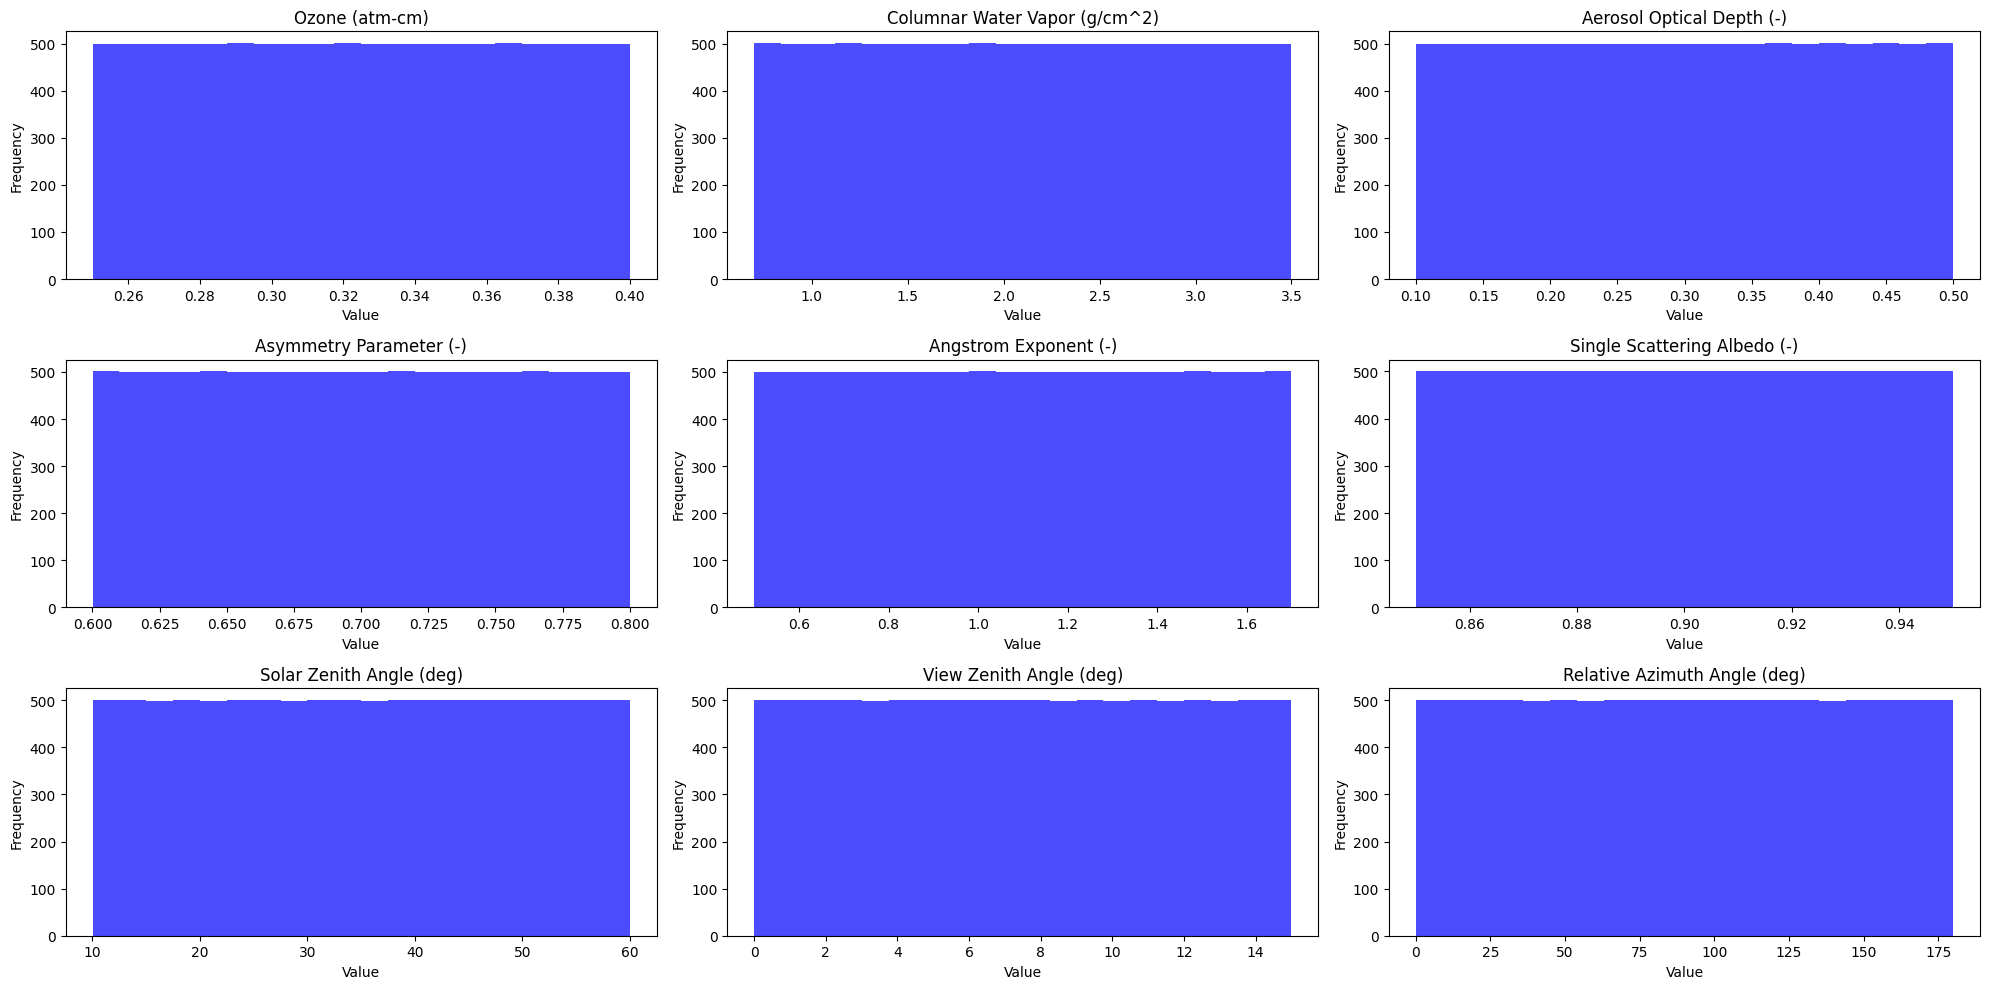

In [7]:
# visualize distribution of all 9 input parameters
plt.figure(figsize=(20, 10))
for i in range(globals.N_INPUTS):
    plt.subplot(3, 3, i+1)
    plt.hist(X[:, i], bins=20, color="blue", alpha=0.7)
    plt.title(globals.param_names_plots[i])
    plt.xlabel("Value")
    plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

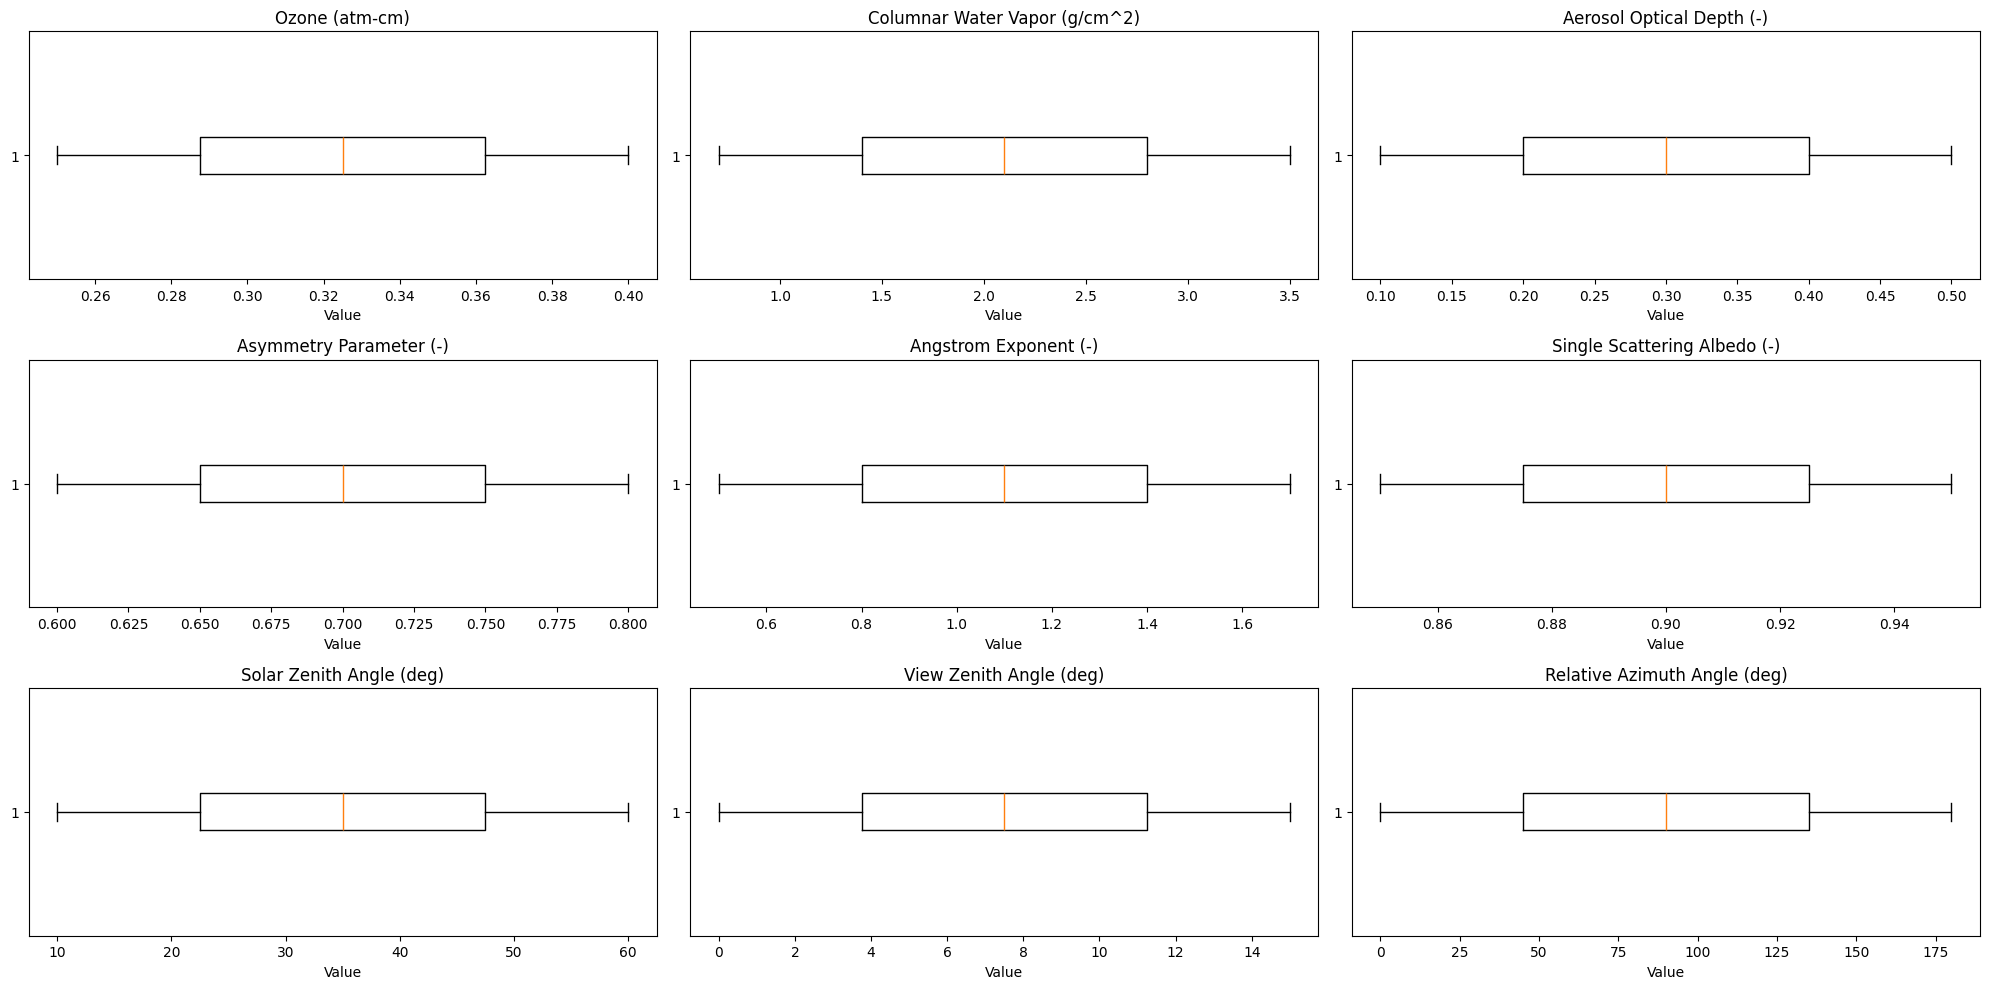

In [8]:
# detect potential outliers in the input parameters using boxplots
plt.figure(figsize=(20, 10))
for i in range(globals.N_INPUTS):
    plt.subplot(3, 3, i+1)
    plt.boxplot(X[:, i], vert=False)
    plt.title(globals.param_names_plots[i])
    plt.xlabel("Value")
plt.tight_layout()
plt.show()

Correlation matrix:
                    O3       CWV       AOD  Asy. Param.  Ang. Exp.       SSA       SZA       VZA       RAA
O3           1.000000  0.003477 -0.008687    -0.000276   0.003437  0.006495  0.005746 -0.003886  0.009974
CWV          0.003477  1.000000  0.020567    -0.003784  -0.002312 -0.020823  0.000879  0.001126  0.008246
AOD         -0.008687  0.020567  1.000000    -0.007931  -0.009268 -0.006861  0.001936  0.007645 -0.030322
Asy. Param. -0.000276 -0.003784 -0.007931     1.000000   0.023702  0.009547  0.017025 -0.009561  0.002067
Ang. Exp.    0.003437 -0.002312 -0.009268     0.023702   1.000000  0.015996  0.015064 -0.014986 -0.002086
SSA          0.006495 -0.020823 -0.006861     0.009547   0.015996  1.000000  0.004168  0.019229  0.009600
SZA          0.005746  0.000879  0.001936     0.017025   0.015064  0.004168  1.000000  0.018569  0.017264
VZA         -0.003886  0.001126  0.007645    -0.009561  -0.014986  0.019229  0.018569  1.000000  0.011679
RAA          0.009974  0.

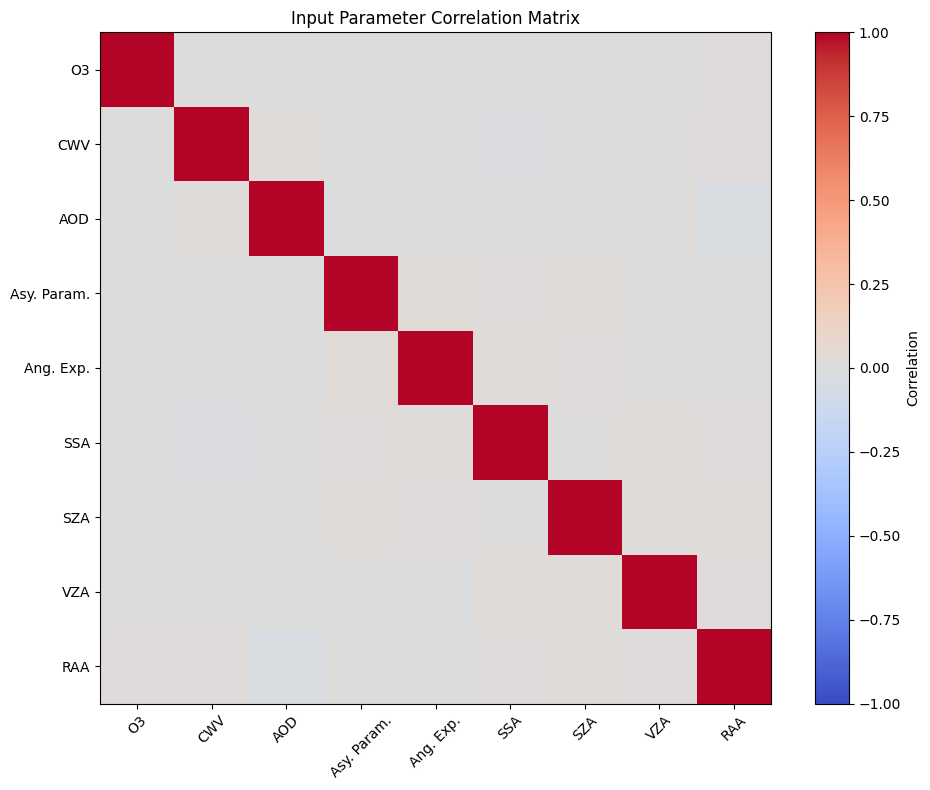

In [9]:
# visualize potential correlations between input parameters
corr = pd.DataFrame(X, columns=globals.param_names_plots_abb).corr()

print("Correlation matrix:\n", corr)

plt.figure(figsize=(10,8))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")

plt.xticks(range(len(globals.param_names_plots_abb)), globals.param_names_plots_abb, rotation=45)
plt.yticks(range(len(globals.param_names_plots_abb)), globals.param_names_plots_abb)

plt.title("Input Parameter Correlation Matrix")
plt.tight_layout()
plt.show()

#### Outputs Analysis

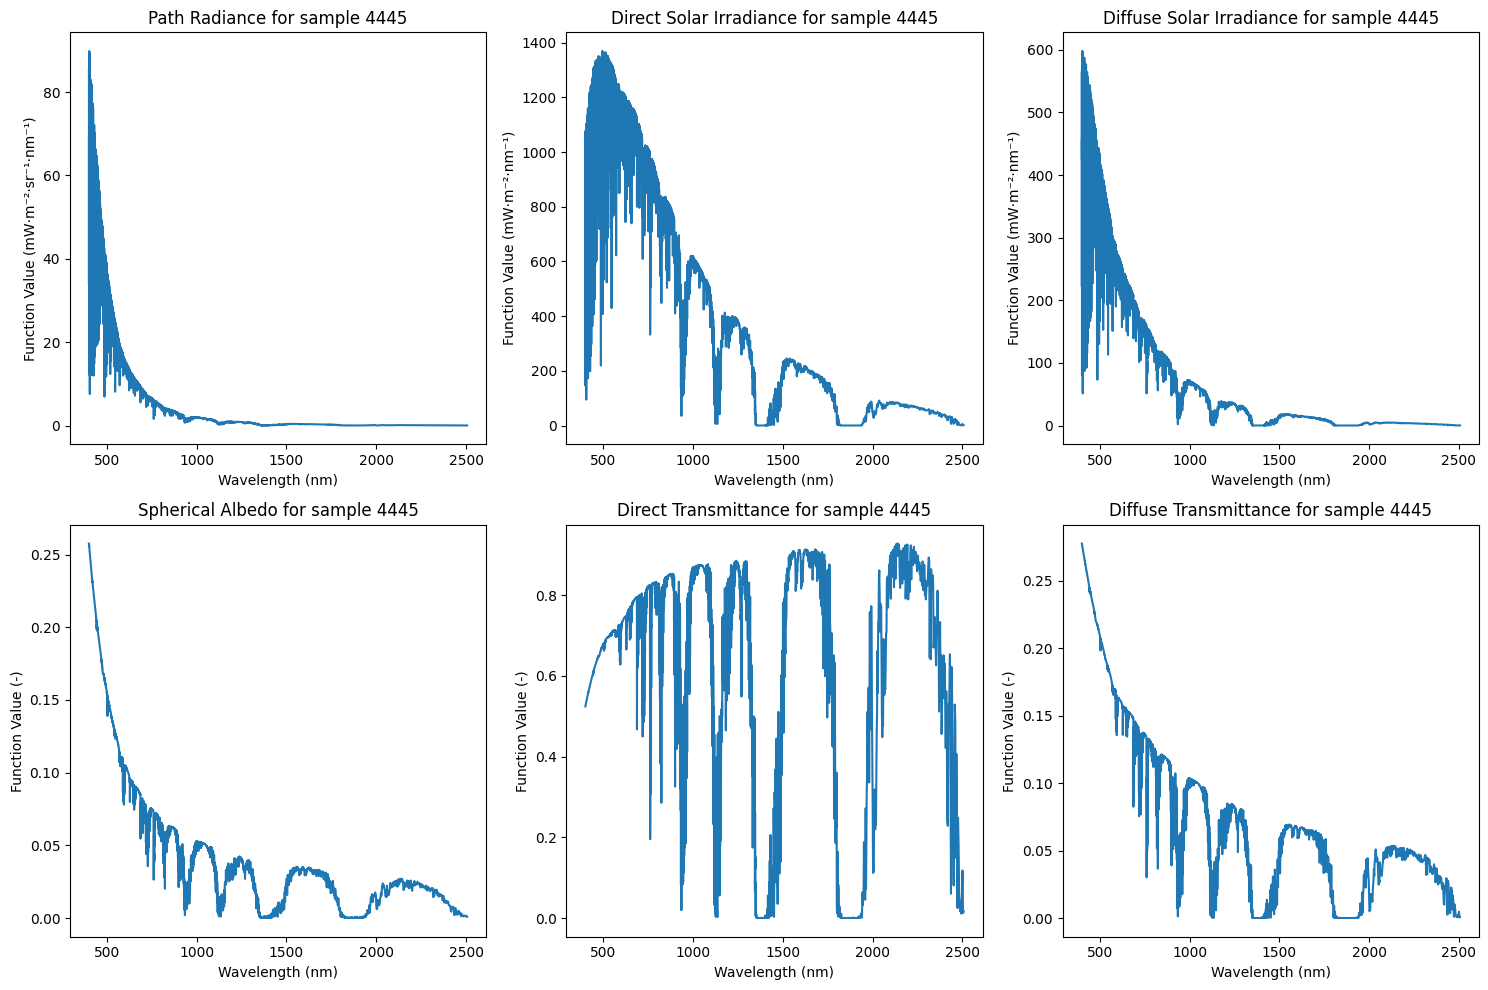

In [10]:
# visualize outputs for a random sample in different subplots
sample_idx = np.random.randint(Y_resh.shape[0])
plt.figure(figsize=(15, 10))
for i in range(globals.N_FUNCTIONS):
    plt.subplot(2, 3, i+1)
    plt.plot(wavelengths, Y_resh[sample_idx, i, :])
    plt.title(f"{globals.function_names_plots[i]} for sample {sample_idx}")
    plt.xlabel("Wavelength (nm)")
    plt.ylabel("Function Value (" + globals.function_units_plots[i] + ")")
plt.tight_layout()
plt.show()

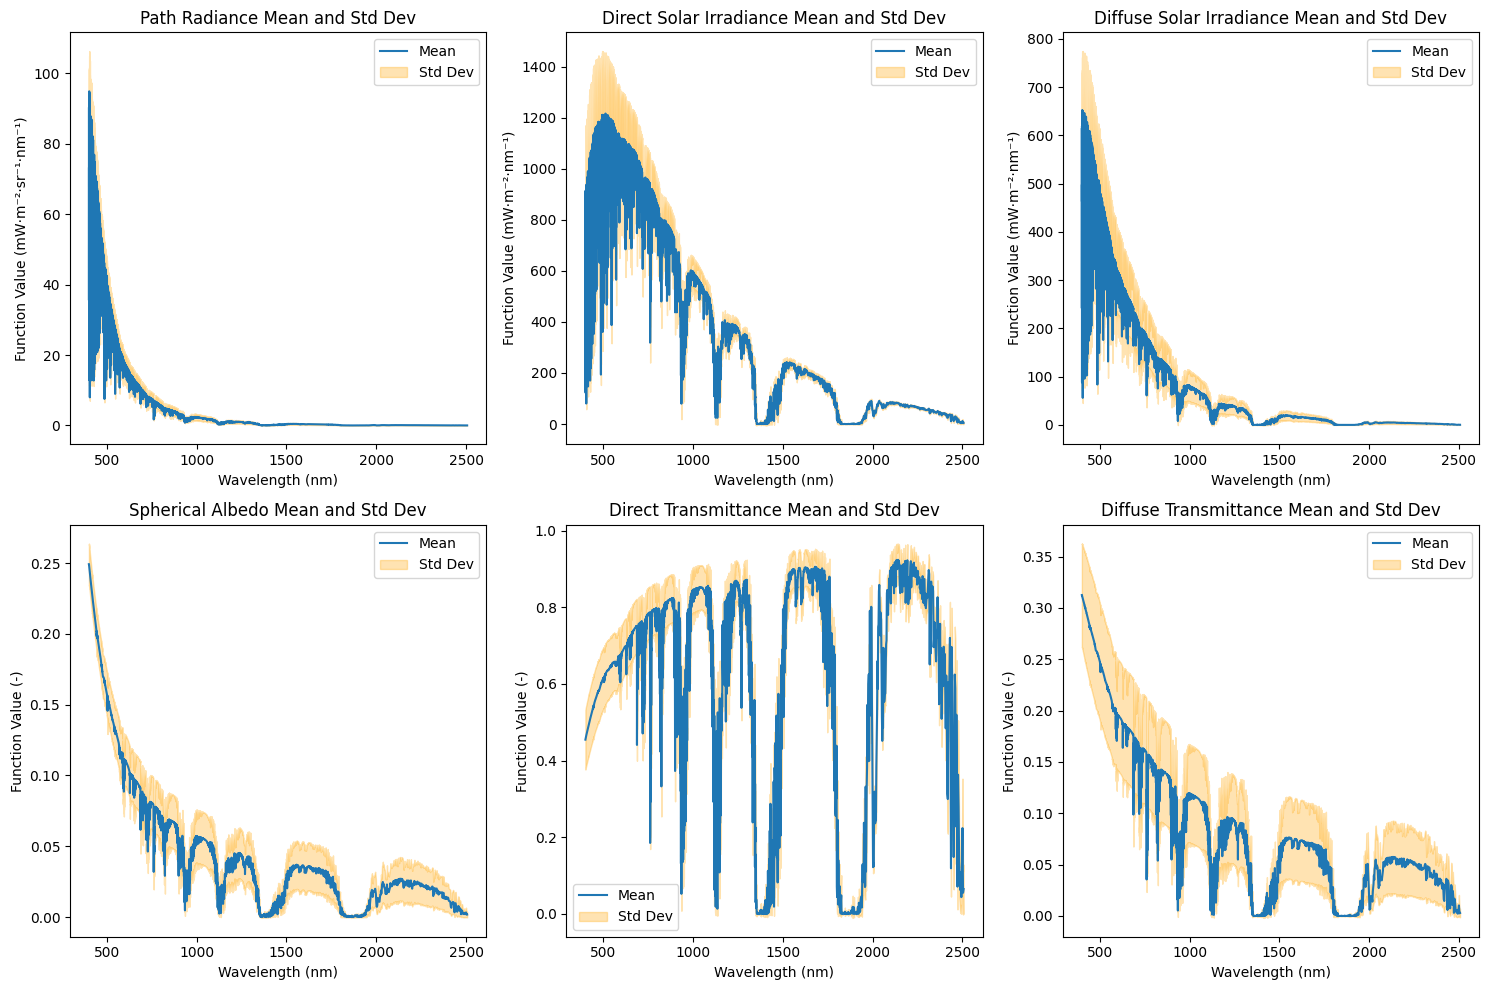

In [11]:
# visualize the mean and standard deviation band of the six functions for all outputs
plt.figure(figsize=(15, 10))
for i in range(globals.N_FUNCTIONS):
    plt.subplot(2, 3, i+1)
    mean_func = np.mean(Y_resh[:, i, :], axis=0)
    std_func = np.std(Y_resh[:, i, :], axis=0)
    plt.plot(wavelengths, mean_func, label="Mean")
    plt.fill_between(wavelengths, mean_func - std_func, mean_func + std_func, color="orange", alpha=0.3, label="Std Dev")
    plt.title(f"{globals.function_names_plots[i]} Mean and Std Dev")
    plt.xlabel("Wavelength (nm)")
    plt.ylabel("Function Value (" + globals.function_units_plots[i] + ")")
    plt.legend()
plt.tight_layout()
plt.show()

Correlation between output functions:
 [[ 1.      0.4873  0.9037  0.9213 -0.2183  0.8047]
 [ 0.4873  1.      0.6374  0.5406  0.3289  0.5103]
 [ 0.9037  0.6374  1.      0.8967 -0.1503  0.9125]
 [ 0.9213  0.5406  0.8967  1.     -0.1     0.9271]
 [-0.2183  0.3289 -0.1503 -0.1     1.     -0.0595]
 [ 0.8047  0.5103  0.9125  0.9271 -0.0595  1.    ]]


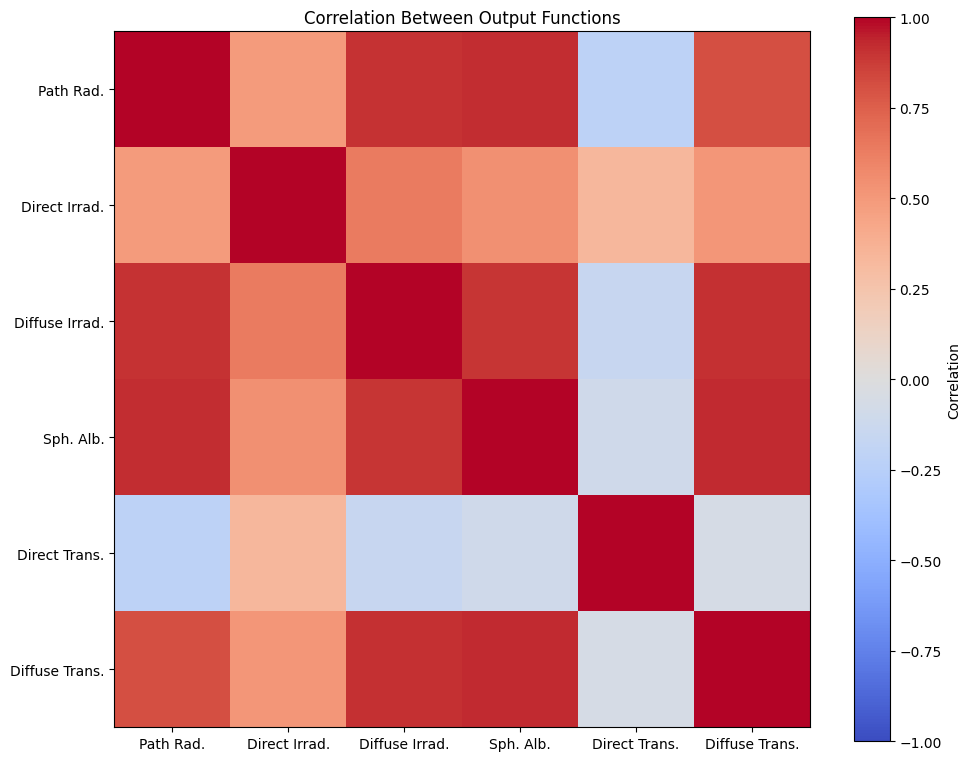

In [12]:
# explore correlation between the six output functions across all samples and wavelengths

# reshape to (6, n_samples * n_wavelengths)
Y_flat = Y_resh.transpose(1, 0, 2).reshape(6, -1)

corr_outputs = np.corrcoef(Y_flat)

print("Correlation between output functions:\n", corr_outputs)

plt.figure(figsize=(10, 8))
plt.imshow(corr_outputs, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")

plt.xticks(range(6), [f"{globals.function_names_plots_abb[i]}" for i in range(6)])
plt.yticks(range(6), [f"{globals.function_names_plots_abb[i]}" for i in range(6)])

plt.title("Correlation Between Output Functions")
plt.tight_layout()
plt.show()

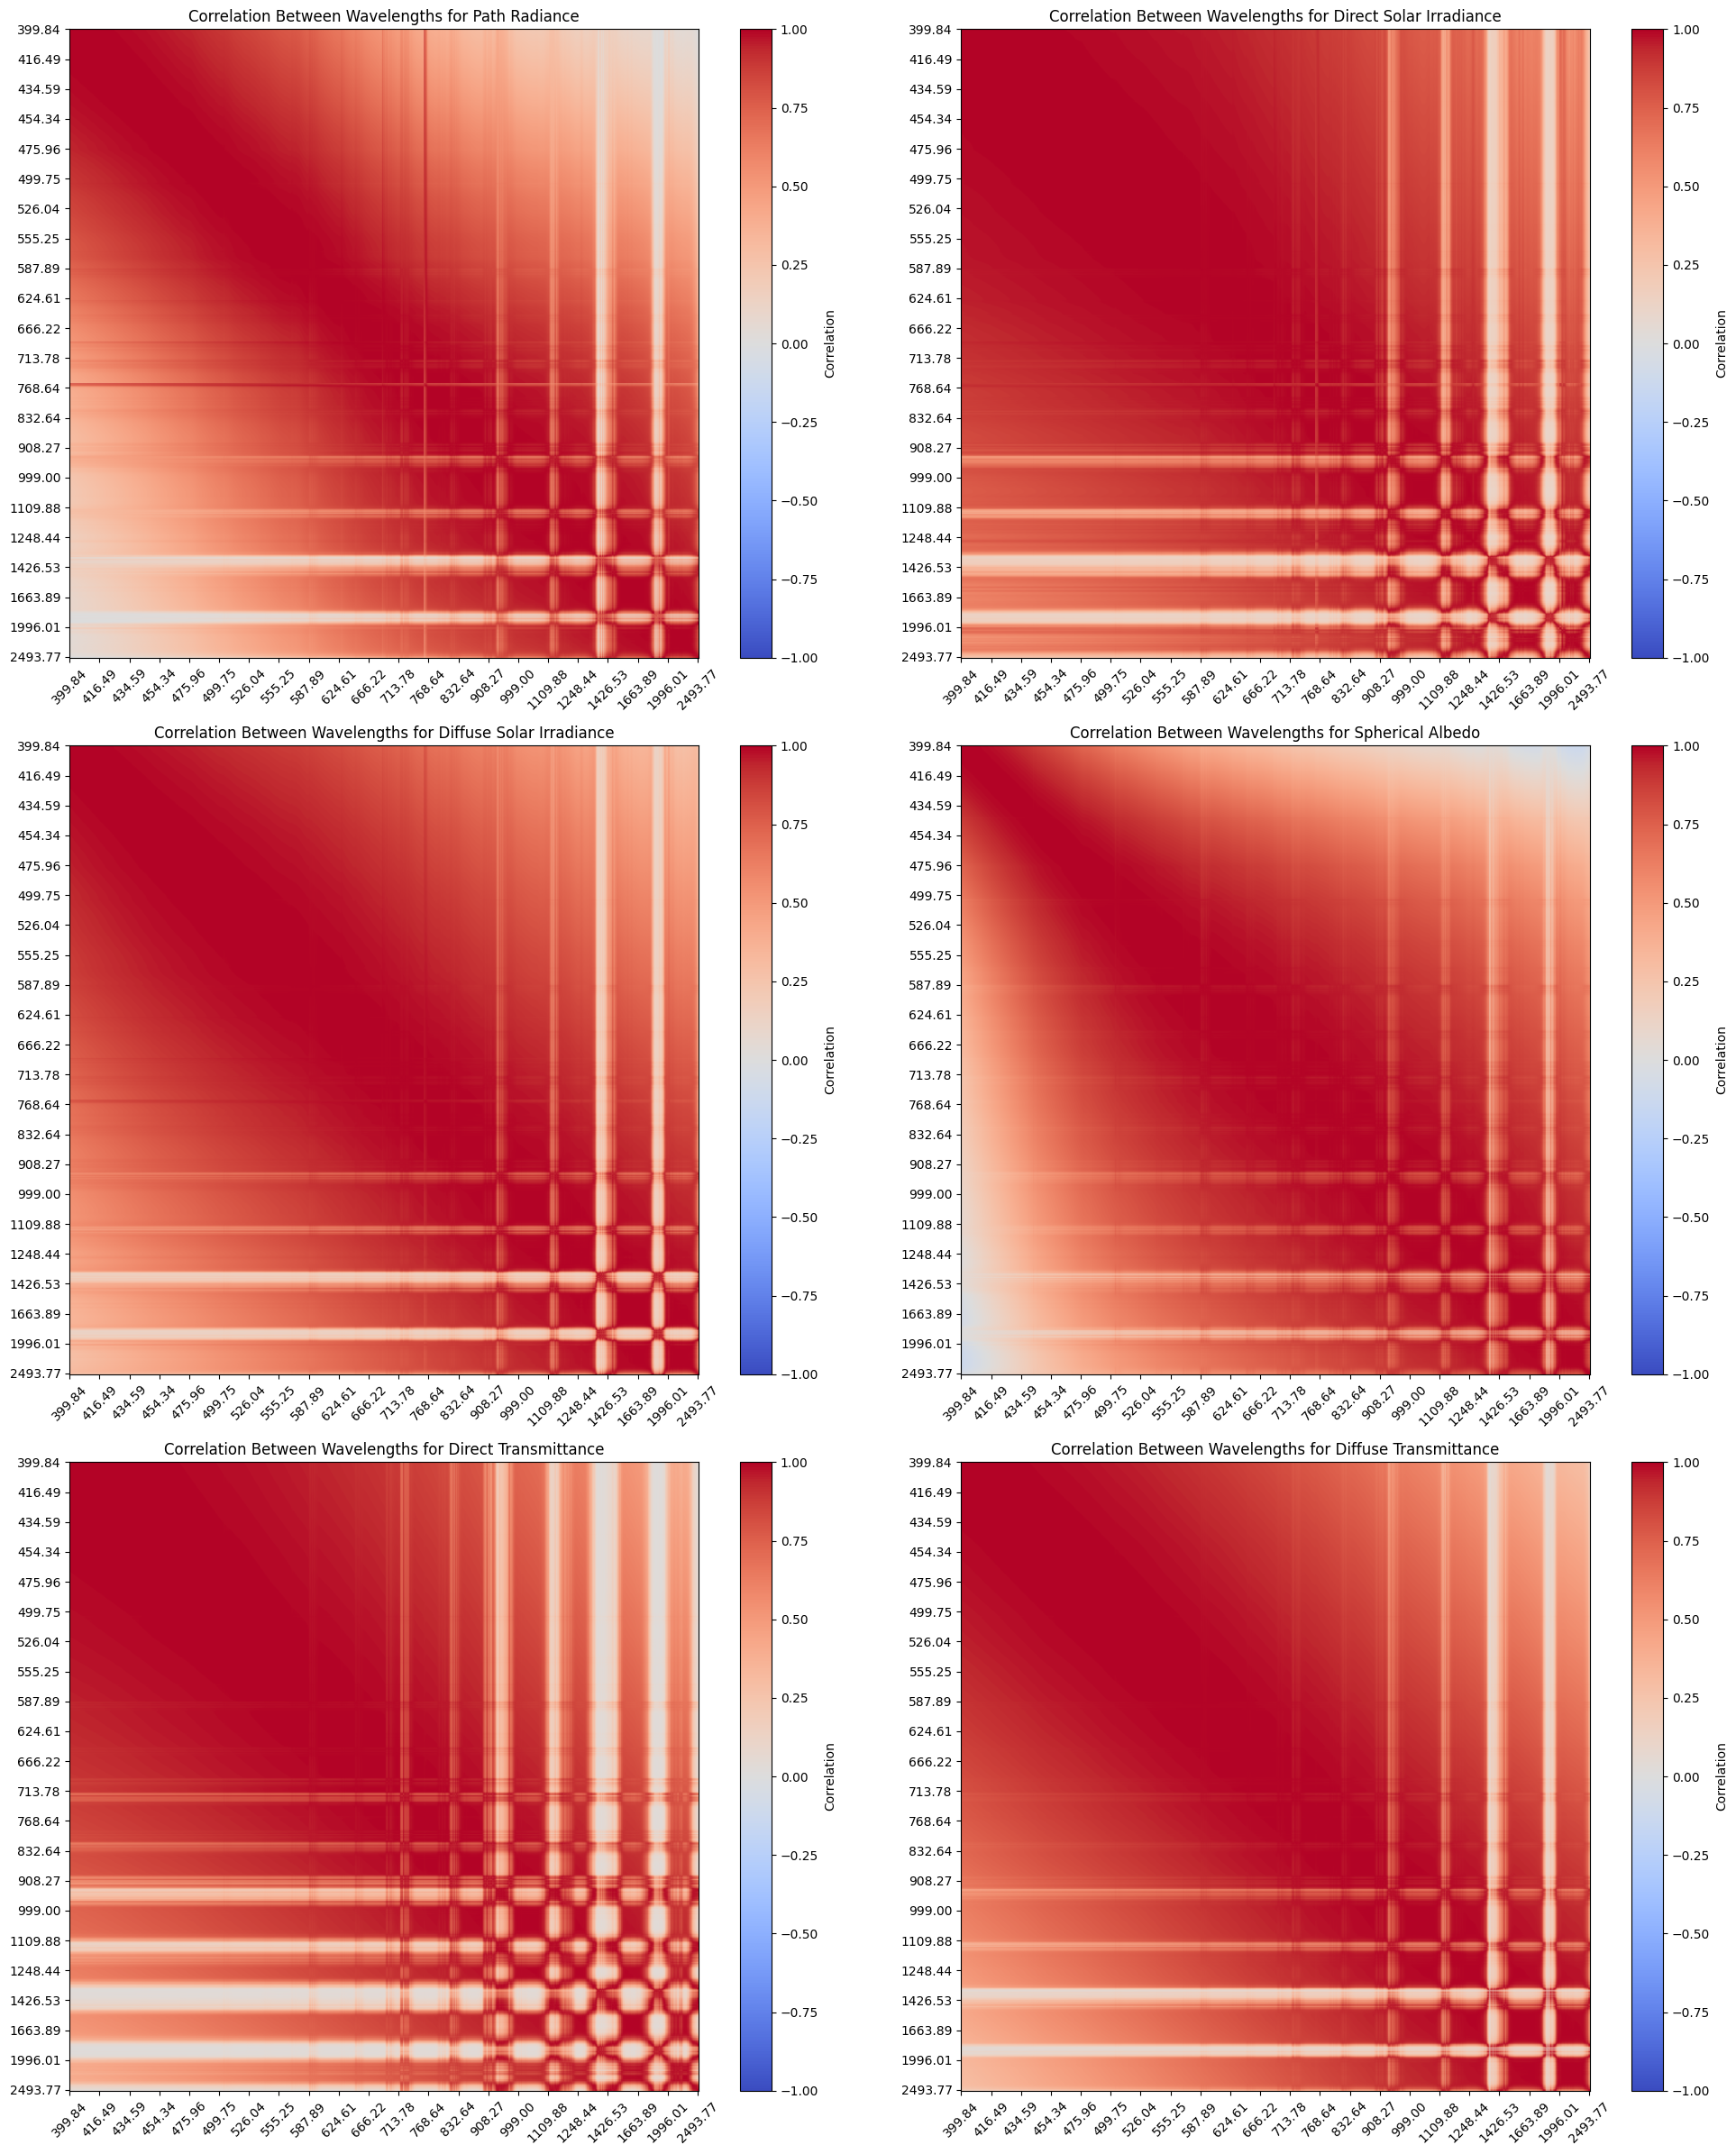

In [13]:
# explore correlation between wavelengths for each function across all samples
fig, axes = plt.subplots(3, 2, figsize=(20, 24))
axes = axes.flatten()

for i in range(globals.N_FUNCTIONS):

    Y_func = Y_resh[:, i, :]  # shape (n_samples, n_wavelengths)
    corr_wavelengths = np.corrcoef(Y_func.T)  # shape (n_wavelengths, n_wavelengths)

    ax = axes[i]
    im = ax.imshow(corr_wavelengths, cmap="coolwarm", vmin=-1, vmax=1)
    fig.colorbar(im, ax=ax, label="Correlation")

    step = 200
    ticks = np.arange(0, len(wavelengths), step)
    ax.set_xticks(ticks, [f"{w:.2f}" for w in wavelengths[::step]], rotation=45)
    ax.set_yticks(ticks, [f"{w:.2f}" for w in wavelengths[::step]])

    ax.set_title(f"Correlation Between Wavelengths for {globals.function_names_plots[i]}")

plt.tight_layout()
plt.show()

#### Train-Val split

In [30]:
X_tr, X_val, X_test, Y_tr, Y_val, Y_test = utils.train_val_test_split(X, Y_resh, wavelengths, verbose=True)

X shape: (10000, 9)
Y shape: (10000, 6, 4205)
wavelengths shape: (4205,)

X_tr shape: (8000, 9)
X_val shape: (1000, 9)
X_test shape: (1000, 9)

Y_tr shape: (8000, 6, 4205)
Y_val shape: (1000, 6, 4205)
Y_test shape: (1000, 6, 4205)


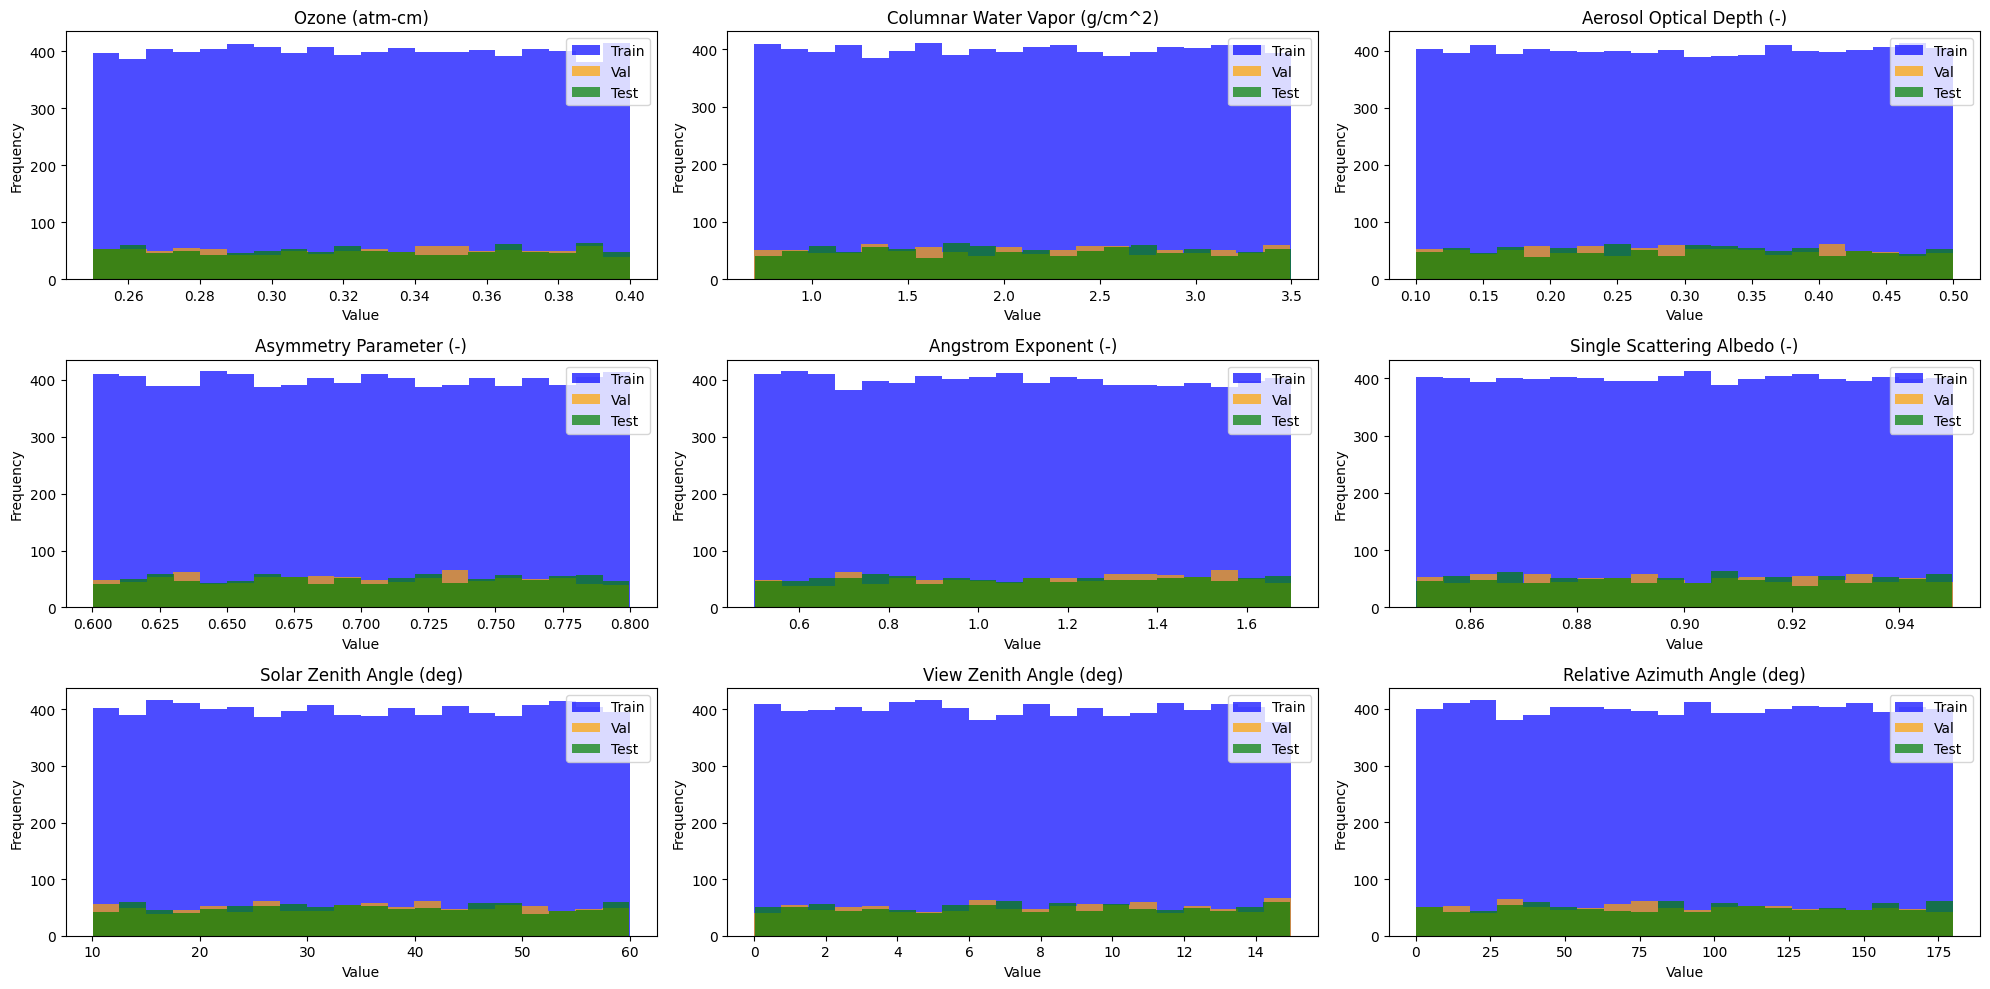

In [31]:
# overlay histograms of input train and val parameters to check if they have similar distributions
plt.figure(figsize=(20, 10))
for i in range(X_tr.shape[1]):
    plt.subplot(3, 3, i+1)
    plt.hist(X_tr[:, i], bins=20, color="blue", alpha=0.7, label="Train")
    plt.hist(X_val[:, i], bins=20, color="orange", alpha=0.7, label="Val")
    plt.hist(X_test[:, i], bins=20, color="green", alpha=0.7, label="Test")
    plt.title(globals.param_names_plots[i])
    plt.xlabel("Value")
    plt.ylabel("Frequency")
    plt.legend()
plt.tight_layout()
plt.show()

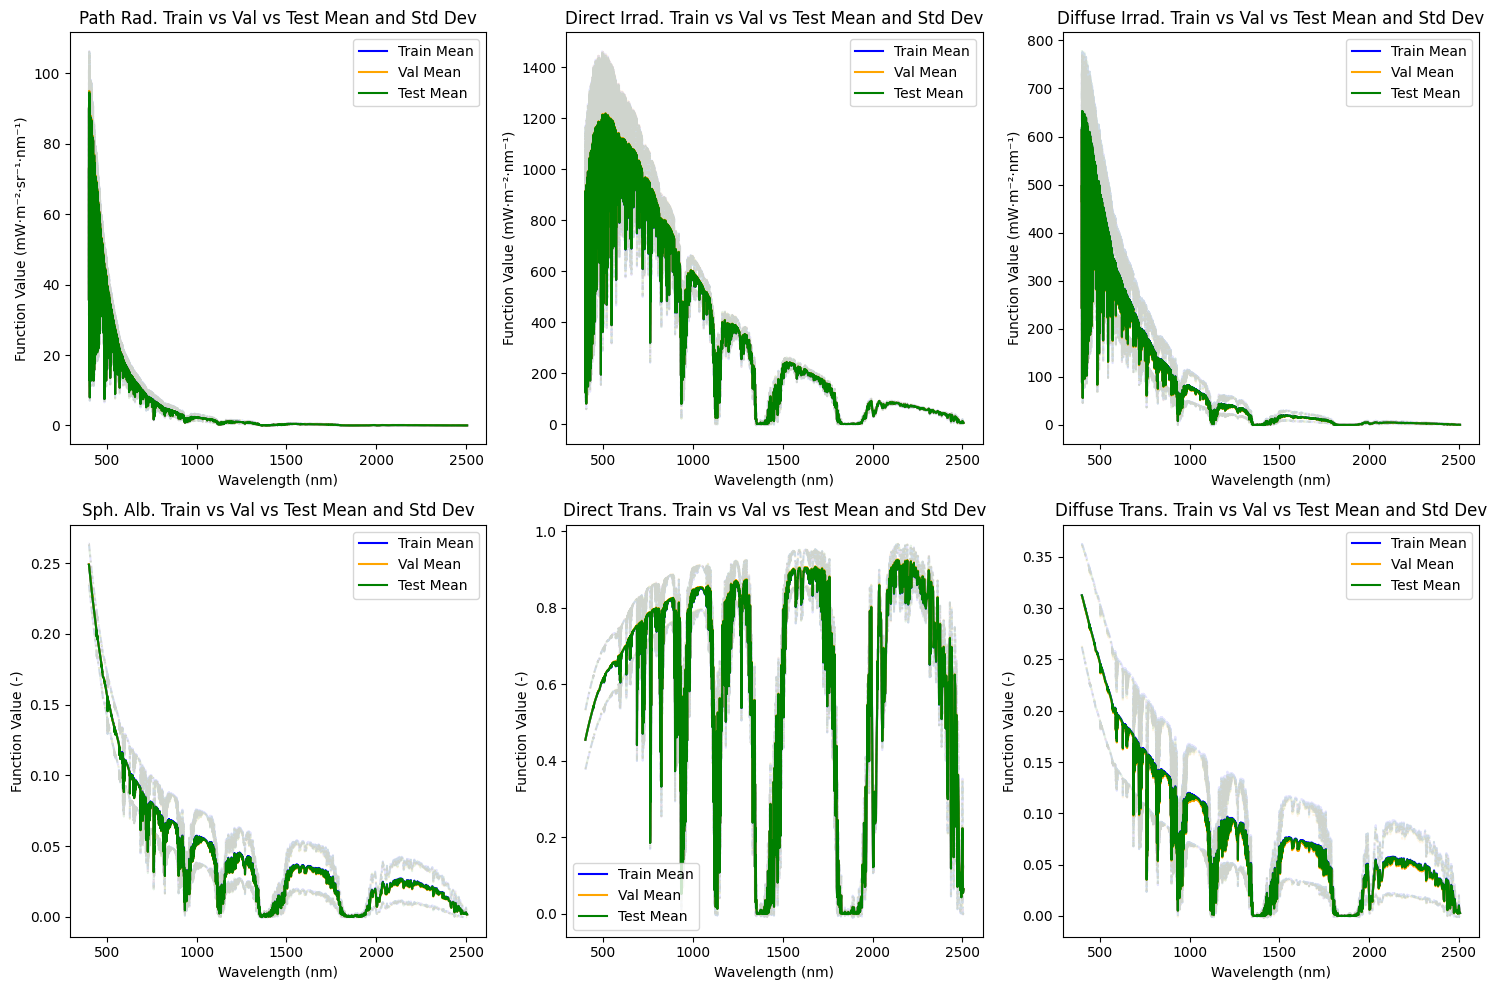

In [32]:
# overlay mean and std dev of train and val outputs to check if they have similar distributions
plt.figure(figsize=(15, 10))
for i in range(Y_tr.shape[1]):
    plt.subplot(2, 3, i+1)
    mean_tr = np.mean(Y_tr[:, i, :], axis=0)
    std_tr = np.std(Y_tr[:, i, :], axis=0)
    mean_val = np.mean(Y_val[:, i, :], axis=0)
    std_val = np.std(Y_val[:, i, :], axis=0)
    mean_test = np.mean(Y_test[:, i, :], axis=0)
    std_test = np.std(Y_test[:, i, :], axis=0)
    
    plt.plot(wavelengths, mean_tr, label="Train Mean", color="blue")
    plt.plot(wavelengths, mean_tr + std_tr, color="blue", linestyle="--", alpha=0.1)
    plt.plot(wavelengths, mean_tr - std_tr, color="blue", linestyle="--", alpha=0.1)
    
    plt.plot(wavelengths, mean_val, label="Val Mean", color="orange")
    plt.plot(wavelengths, mean_val + std_val, color="orange", linestyle=":", alpha=0.1)
    plt.plot(wavelengths, mean_val - std_val, color="orange", linestyle=":", alpha=0.1)

    plt.plot(wavelengths, mean_test, label="Test Mean", color="green")
    plt.plot(wavelengths, mean_test + std_test, color="green", linestyle="-.", alpha=0.1)
    plt.plot(wavelengths, mean_test - std_test, color="green", linestyle="-.", alpha=0.1)
    
    plt.title(f"{globals.function_names_plots_abb[i]} Train vs Val vs Test Mean and Std Dev")
    plt.xlabel("Wavelength (nm)")
    plt.ylabel("Function Value (" + globals.function_units_plots[i] + ")")
    plt.legend()
plt.tight_layout()
plt.show()

#### Inspect AMLEC test data

In [33]:
print("X_test_amlec_interp (first 5 rows):\n", X_test_amlec_interp[:5])
print()

print("X_test_amlec_interp stats:")
print("  min:", X_test_amlec_interp.min(axis=0))
print("  max:", X_test_amlec_interp.max(axis=0))
print("  mean:", X_test_amlec_interp.mean(axis=0))
print("  std:", X_test_amlec_interp.std(axis=0))

X_test_amlec_interp (first 5 rows):
 [[  0.3779   1.0788   0.2922   0.7482   1.5655   0.9352  48.8664  14.5398 147.2386]
 [  0.2674   1.986    0.2154   0.7375   1.3401   0.9375  58.2269   5.0088   1.5536]
 [  0.2774   1.0586   0.4879   0.751    1.2538   0.9138  46.0178   6.6077   8.6624]
 [  0.3795   1.1899   0.433    0.7588   0.8247   0.909   25.9503  12.4342  83.1263]
 [  0.3686   2.3395   0.3111   0.748    0.8596   0.8598  20.6911   4.1335  39.2197]]

X_test_amlec_interp stats:
  min: [ 0.25    0.7001  0.1     0.6     0.5     0.85   10.0036  0.0007  0.0174]
  max: [  0.4      3.4999   0.5      0.8      1.6999   0.95    59.9994  14.9987 179.984 ]
  mean: [ 0.325   2.1     0.3     0.7     1.1     0.9    35.      7.5    89.9999]
  std: [ 0.0433  0.8083  0.1155  0.0577  0.3464  0.0289 14.4338  4.3301 51.9615]


In [34]:
print("X_test_amlec_extrap (first 5 rows):\n", X_test_amlec_extrap[:5])
print()

print("X_test_amlec_extrap stats:")
print("  min:", X_test_amlec_extrap.min(axis=0))
print("  max:", X_test_amlec_extrap.max(axis=0))
print("  mean:", X_test_amlec_extrap.mean(axis=0))
print("  std:", X_test_amlec_extrap.std(axis=0))

X_test_amlec_extrap (first 5 rows):
 [[  0.4349   3.8256   0.5865   0.8324   1.7578   0.9952  60.7899   8.5779 122.1523]
 [  0.427    3.6055   0.5951   0.8124   1.8907   0.957   68.7246   8.8419  39.4363]
 [  0.4139   3.7614   0.5141   0.8376   1.77     0.9674  60.2616  10.9045 174.3961]
 [  0.431    3.8337   0.5831   0.84     1.8006   0.9826  69.8881   0.6329  30.9091]
 [  0.4193   3.8616   0.5737   0.8212   1.9404   0.993   69.0357   8.7653  20.1623]]

X_test_amlec_extrap stats:
  min: [0.2    0.2001 0.04   0.5    0.1001 0.8    0.0011 0.003  0.0241]
  max: [  0.45     3.9999   0.6      0.85     1.9999   1.      69.9986  14.9997 179.9824]
  mean: [ 0.325   2.1     0.31    0.6875  1.075   0.9    35.      7.5    90.0006]
  std: [ 0.101   1.6563  0.2412  0.1394  0.7817  0.0764 30.1385  4.3301 51.9611]


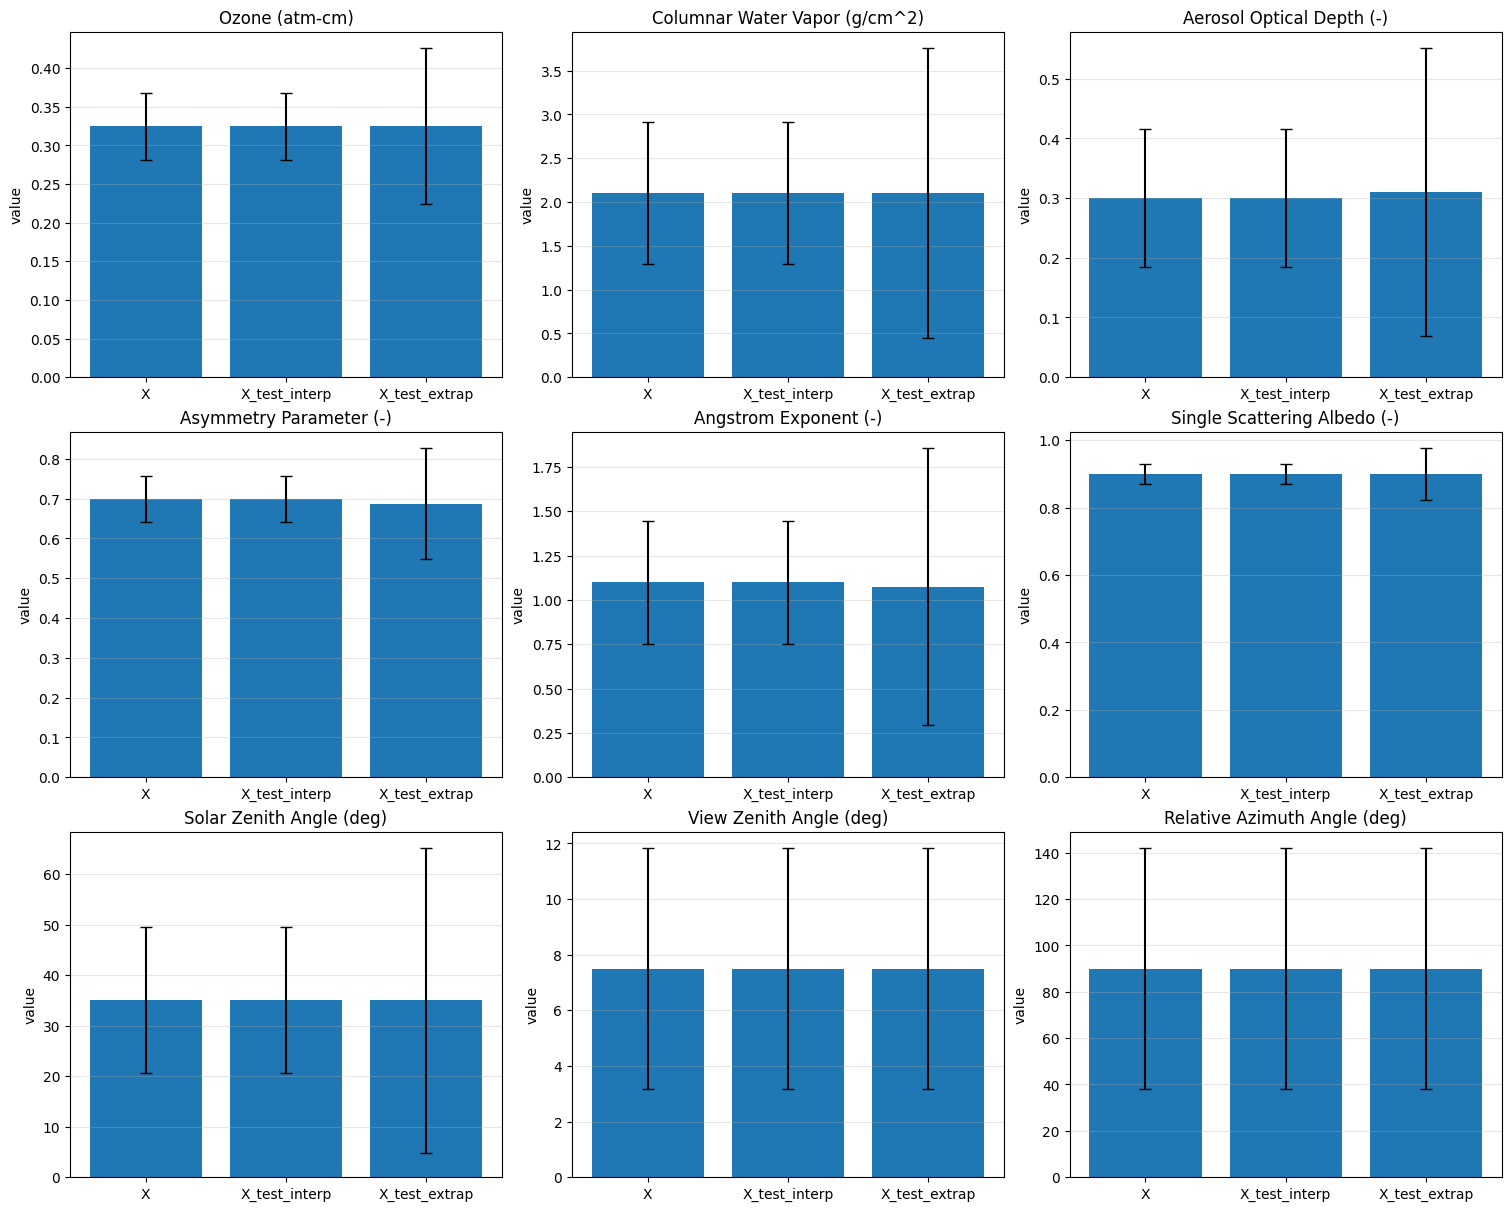

In [35]:
datasets = {"X": X, "X_test_interp": X_test_amlec_interp, "X_test_extrap": X_test_amlec_extrap}

means = {name: data.mean(axis=0) for name, data in datasets.items()}
stds = {name: data.std(axis=0) for name, data in datasets.items()}

n_features = X.shape[1]

fig, axes = plt.subplots(3, 3, figsize=(15, 12), constrained_layout=True)
axes = axes.flatten()
x = np.arange(len(datasets))
labels = list(datasets.keys())
for feature_idx, ax in enumerate(axes[:n_features]):
    feature_means = [means[name][feature_idx] for name in labels ]
    feature_stds = [ stds[name][feature_idx] for name in labels ]
    
    ax.bar(x, feature_means, yerr=feature_stds, capsize=4)
    
    ax.set_title(f"{globals.param_names_plots[feature_idx]}")
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_ylabel("value")
    ax.grid(axis="y", alpha=0.3)

plt.show()

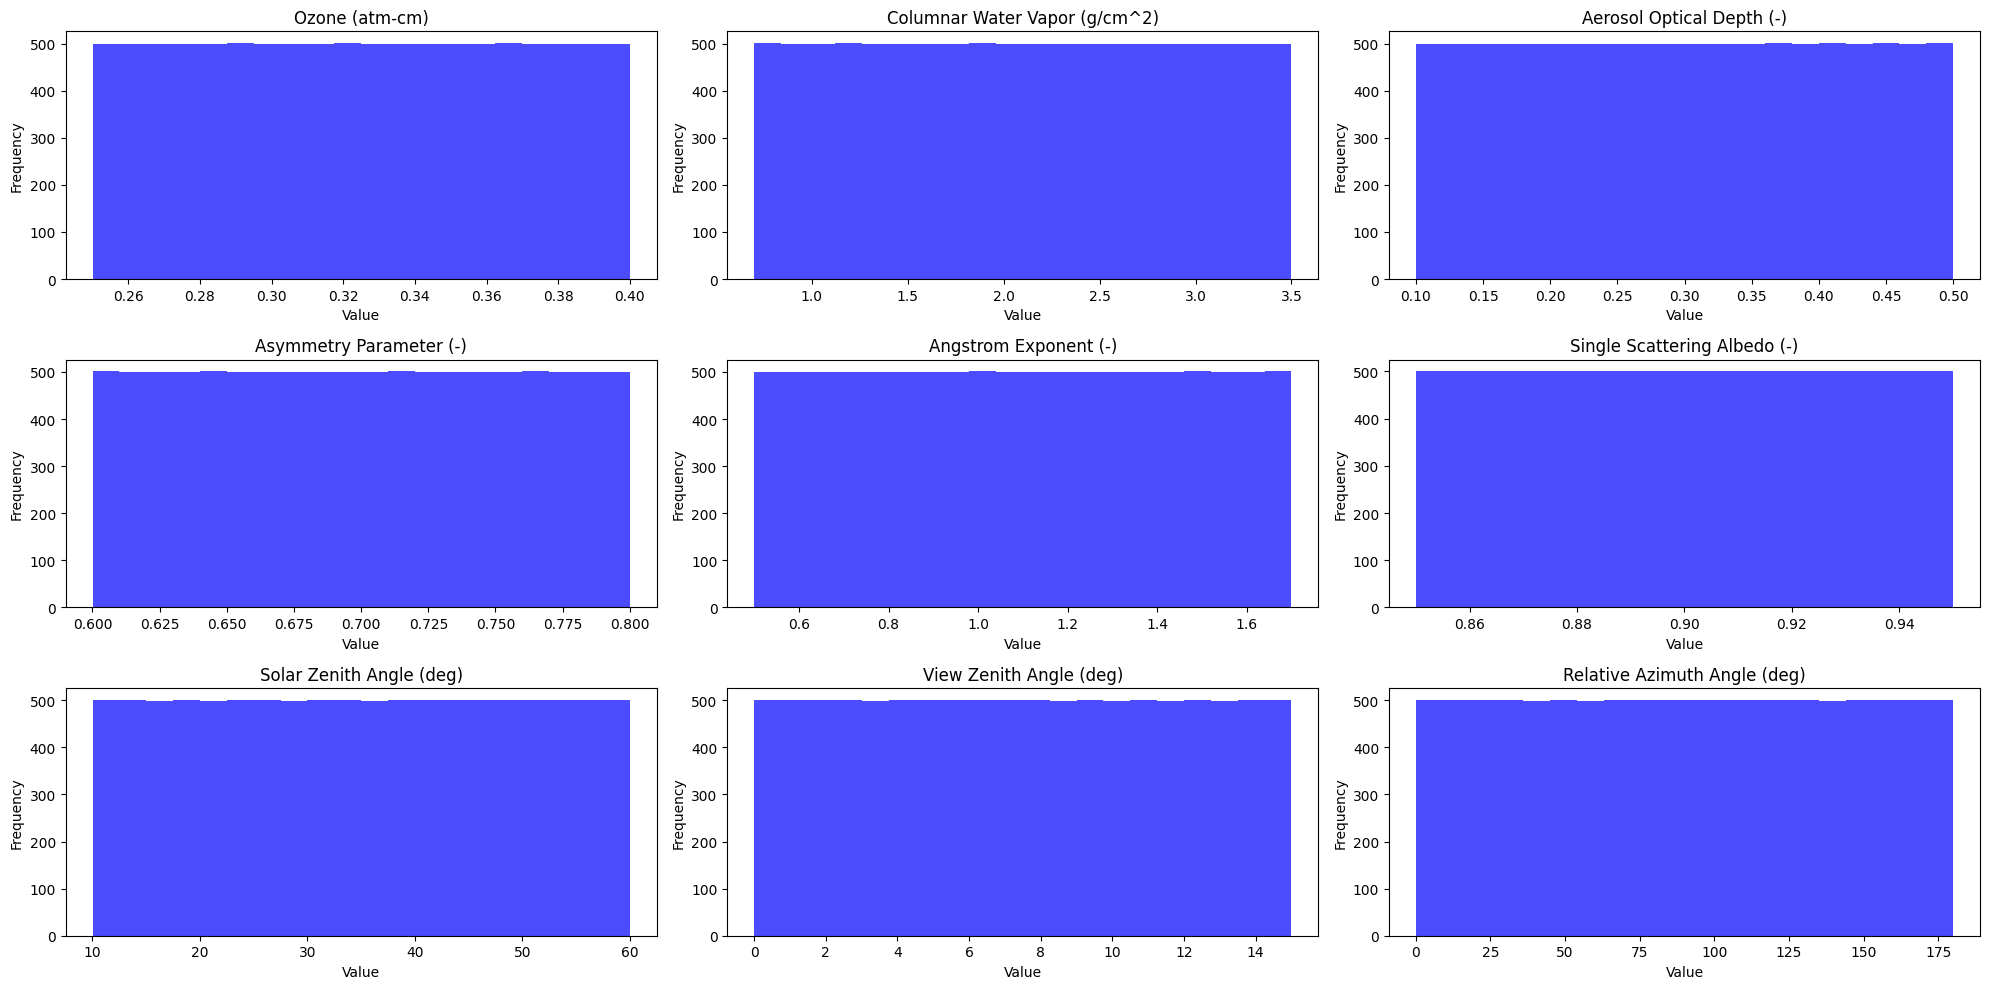

In [36]:
# visualize distribution of all 9 input parameters
plt.figure(figsize=(20, 10))
for i in range(globals.N_INPUTS):
    plt.subplot(3, 3, i+1)
    plt.hist(X_test_amlec_interp[:, i], bins=20, color="blue", alpha=0.7)
    plt.title(globals.param_names_plots[i])
    plt.xlabel("Value")
    plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

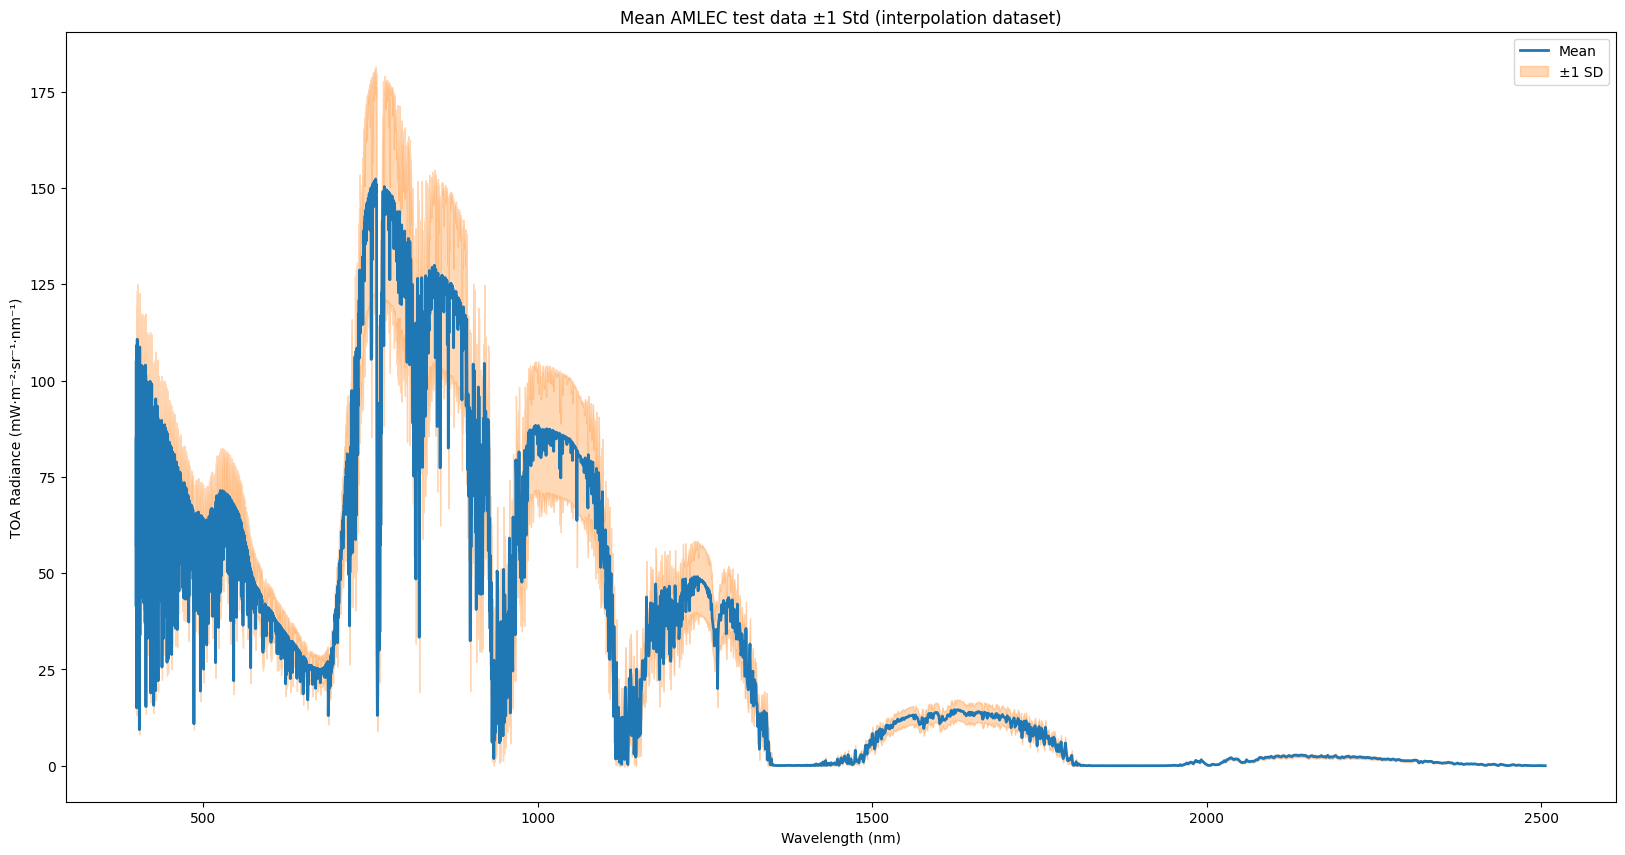

In [ ]:
# toa radiance visualization
mean_spectrum = np.mean(Y_test_amlec_interp, axis=0)
std_spectrum = np.std(Y_test_amlec_interp, axis=0)

plt.figure(figsize=(20, 10))
plt.plot(wavelengths, mean_spectrum, color='C0', linewidth=2, label='Mean')
plt.fill_between(wavelengths, mean_spectrum - std_spectrum, mean_spectrum + std_spectrum, color='C1', alpha=0.3, label='±1 SD')

plt.title("Mean AMLEC test data ±1 Std (interpolation dataset)")
plt.xlabel("Wavelength (nm)")
plt.ylabel('TOA Radiance (mW·m⁻²·sr⁻¹·nm⁻¹)')
plt.legend()
plt.show()

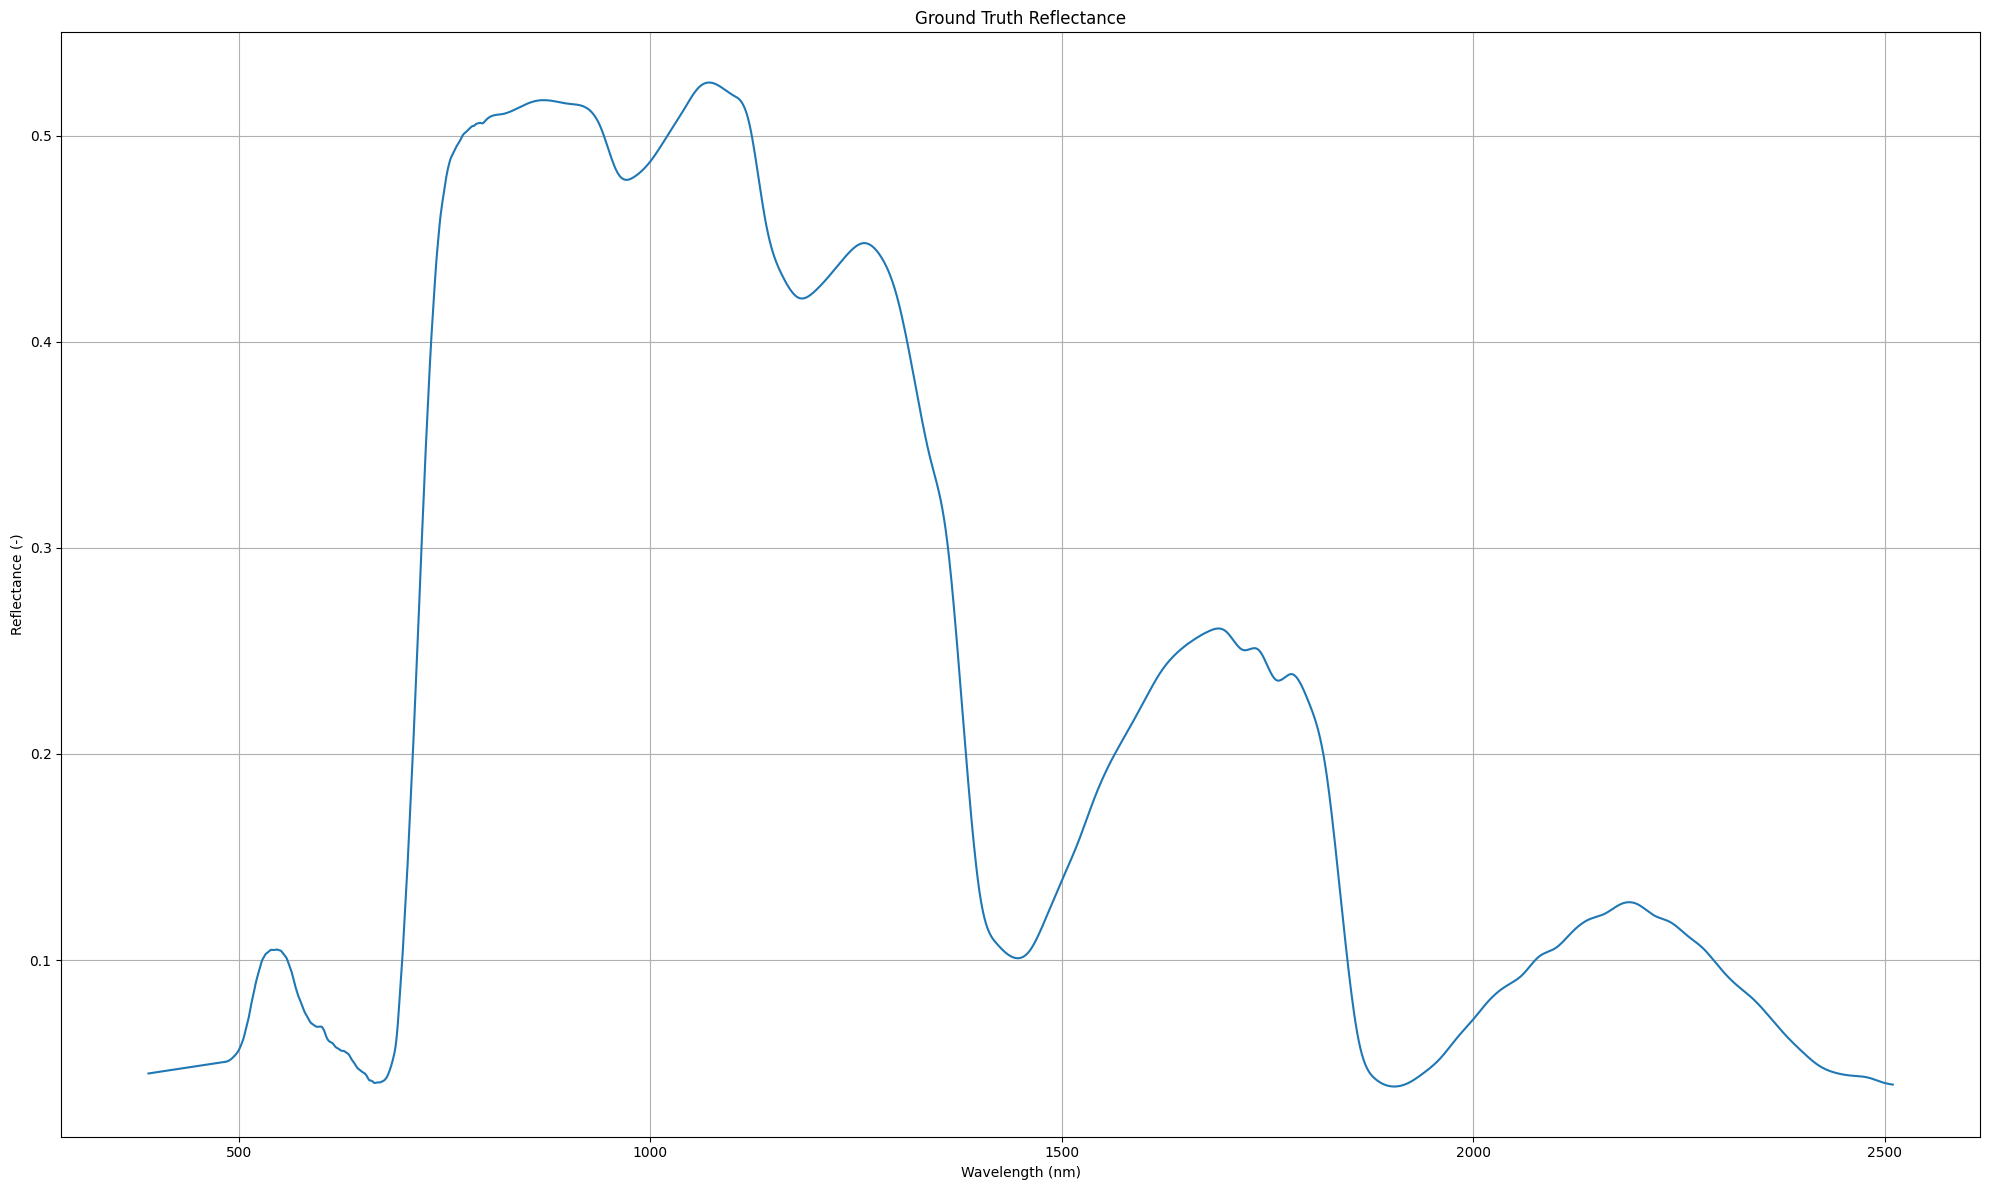

In [ ]:
# plot the reference reflectance data
file_path = globals.REF_LDB
data = pd.read_csv(file_path, header=None, names=['Wavelength', 'Column 1', 'Column 2'])

plt.figure(figsize=(20, 12))
plt.plot(data['Wavelength'], data['Column 1'], color='tab:blue')
# plt.plot(data['Wavelength'], data['Column 2'], label='Column 2', color='tab:orange')

plt.xlabel('Wavelength (nm)')
plt.ylabel('Reflectance (-)')
plt.title('Ground Truth Reflectance')
# plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

#### Inspect PCA reconstruction error

In [26]:
paths = [globals.TRAIN_FILE_A_500, globals.TRAIN_FILE_A_2000]#, globals.TRAIN_FILE_A_10000]
errors = []

for path in paths:
    X, Y, wavelengths = utils.load_train_h5(path)
    wavelengths = wavelengths.squeeze()
    Y_resh = Y.reshape(-1, Y.shape[1] // len(wavelengths), len(wavelengths))

    X_tr, X_temp, Y_tr, Y_temp = train_test_split(X, Y_resh, test_size=0.2, shuffle=True, random_state=42)
    X_val, X_test, Y_val, Y_test = train_test_split(X_temp, Y_temp, test_size=0.5, shuffle=True, random_state=42)

    pca_list, Y_tr_pca, Y_val_pca = utils.apply_pca(Y_tr, Y_val, n_components=10, verbose=False)

    Y_tr_recon = np.zeros_like(Y_tr)
    Y_val_recon = np.zeros_like(Y_val)
    for i in range(globals.N_FUNCTIONS):
        Y_tr_recon_single = pca_list[i].inverse_transform(Y_tr_pca[:, i, :])  # inverse PCA
        Y_val_recon_single = pca_list[i].inverse_transform(Y_val_pca[:, i, :])

        Y_tr_recon[:, i, :] = Y_tr_recon_single
        Y_val_recon[:, i, :] = Y_val_recon_single

    tr_mre_recon = utils.mre_score(Y_tr, Y_tr_recon, wavelengths, axis=None)
    tr_mae_recon = utils.mae_score(Y_tr, Y_tr_recon, wavelengths, axis=None)
    val_mre_recon = utils.mre_score(Y_val, Y_val_recon, wavelengths, axis=None)
    val_mae_recon = utils.mae_score(Y_val, Y_val_recon, wavelengths, axis=None)
    errors.append({
        "dataset": path,
        "train_mre": tr_mre_recon,
        "train_mae": tr_mae_recon,
        "val_mre": val_mre_recon,
        "val_mae": val_mae_recon,
    })
    print(f"---Reconstruction errors for dataset {path}---")
    print(f"\tTraining reconstruction MRE: {tr_mre_recon}")
    print(f"\tTraining reconstruction MAE: {tr_mae_recon}")
    print(f"\tValidation reconstruction MRE: {val_mre_recon}")
    print(f"\tValidation reconstruction MAE: {val_mae_recon}\n\n")

---------- Applying PCA with n_components=10 to each function separately... ----------
---------- PCA application completed. ----------

---Reconstruction errors for dataset ..\AMLEC-1\rtm_emulation\scenarioA\train\train500.h5---
	Training reconstruction MRE: 0.0010993721662089229
	Training reconstruction MAE: 0.039955273270606995
	Validation reconstruction MRE: 0.0012079868465662003
	Validation reconstruction MAE: 0.03949465975165367


---------- Applying PCA with n_components=10 to each function separately... ----------
---------- PCA application completed. ----------

---Reconstruction errors for dataset ..\AMLEC-1\rtm_emulation\scenarioA\train\train2000.h5---
	Training reconstruction MRE: 0.0011314308503642678
	Training reconstruction MAE: 0.03891025856137276
	Validation reconstruction MRE: 0.0012029067147523165
	Validation reconstruction MAE: 0.0377180390059948




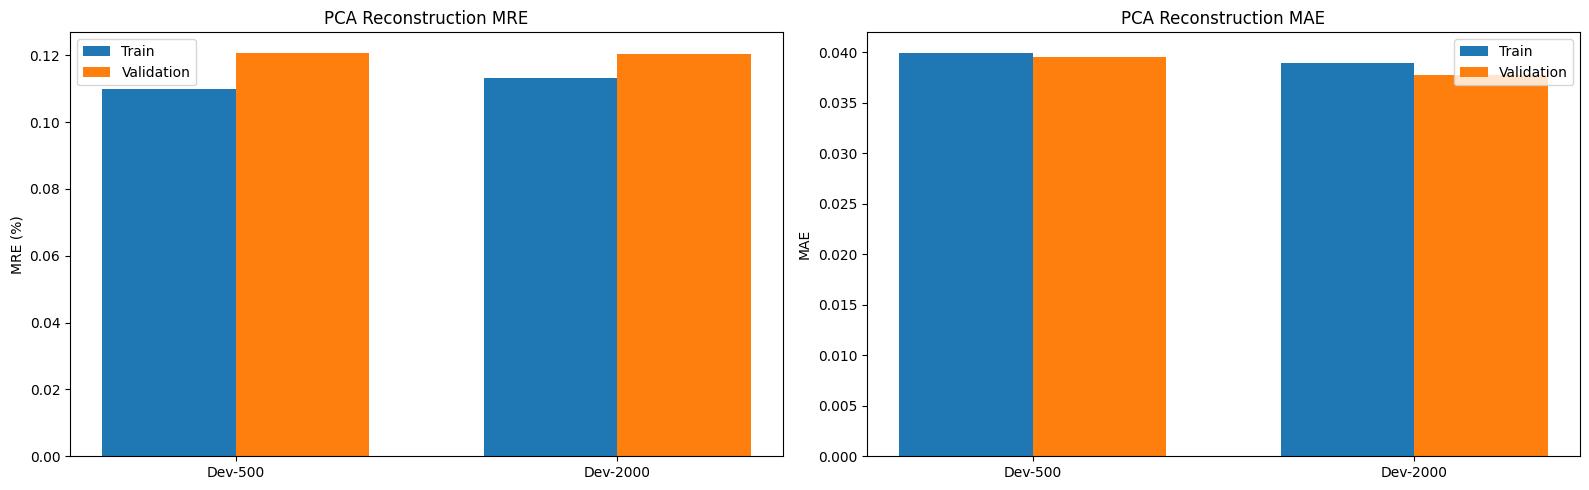

In [29]:
labels = ["Dev-500", "Dev-2000"]#, "Dev-10000"]

train_mre = [r["train_mre"] for r in errors]
val_mre = [r["val_mre"] for r in errors]
train_mae = [r["train_mae"] for r in errors]
val_mae = [r["val_mae"] for r in errors]

x = np.arange(len(labels))
width = 0.35

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharex=True)

# MRE subplot
axes[0].bar(x - width/2, np.array(train_mre) * 100, width, label="Train")
axes[0].bar(x + width/2, np.array(val_mre) * 100, width, label="Validation")
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels)
axes[0].set_ylabel("MRE (%)")
axes[0].set_title("PCA Reconstruction MRE")
axes[0].legend()

# MAE subplot
axes[1].bar(x - width/2, train_mae, width, label="Train")
axes[1].bar(x + width/2, val_mae, width, label="Validation")
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels)
axes[1].set_ylabel("MAE")
axes[1].set_title("PCA Reconstruction MAE")
axes[1].legend()

plt.tight_layout()
plt.show()